# Biermann et al. 2022 — Melanoma brain/peripheral metastasis
## 01 · Preprocessing, integration & Gate 1 (mixing + continuity)

Malignant-cell manifold for a metastatic melanoma atlas (10x, 30 samples: brain-met **MBM** +
peripheral-met **MPM**, single-nucleus `_sn` / single-cell `_sc`). Neural-crest-derived tumour →
the atlas's **low-pSom, Crest-dominant** case. Gate 1 asks whether the malignant structure is both
**mixed** (Harmony-integrated across `sample`) and **continuous** (one connected gradient), judged on
the embedding + a per-neighbourhood metric, not a scalar alone (evaluation-audit lesson).

In [2]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)
import logging
logging.getLogger('harmonypy').setLevel(logging.ERROR)
logging.getLogger('harmonypy').propagate=False
logging.getLogger('harmonypy').disabled=True

In [3]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Biermann2022_Skin | category: Skin


In [4]:
# load dataset -> select malignant cells
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalized 10x counts)' % adata.X.max())
print('met site (source):', adata.obs['source'].value_counts().to_dict())
print('cell_cycle_phase:', adata.obs['cell_cycle_phase'].astype(str).value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Biermann2022_Skin
Done.
full atlas: (136973, 35652)
malignant: (91525, 35652) | samples: 30
expression: X max 7.29 (log1p of normalized 10x counts)
met site (source): {'Peripheral_Metastasis': 56104, 'Brain_Metastasis': 35421}
cell_cycle_phase: {'Not cycling': 74651, 'G1/S': 7180, 'G2/M': 3766, 'nan': 3337, 'Intermediate': 2591}


In [5]:
# threshold per-sample malignant counts: look for a DOMINANT spillover cliff,
# else fall back to the >=100 floor (the cliff premise, C3, must be shown to hold)
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover cliff below ~2x floor?
print('sorted per-sample counts:', n.values)
print(f'biggest gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff: the biggest gap {int(vals[gap])}->{int(vals[gap+1])} lands on a real {int(vals[gap+1])}-cell tumour')
    print(f'  (well above floor), not a spillover shelf -> fall back to >= {FLOOR} floor')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [10043  8132  7723  6686  5808  5283  5127  5059  4101  3378  3276  2950
  2665  2629  2481  2213  2041  1711  1582  1471  1441   996   977   948
   902   842   344   331   224   161]
biggest gap 842->344 (ratio 2.45); top/second = 1.66; dominant cliff = False
no dominant cliff: the biggest gap 842->344 lands on a real 344-cell tumour
  (well above floor), not a spillover shelf -> fall back to >= 100 floor
kept 30/30 samples (min per-sample = 161) -> 91525 cells


In [6]:
# filter genes + select over-dispersed features
sc.pp.filter_genes(adata, min_cells = 3)
scf.pp.find_overdispersed(adata)
print('over-dispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps = 50)
vr = adata.uns['pca']['variance_ratio']
print('PCA variance-ratio (first 12):', np.round(vr[:12], 3))
print('cum var @ 10/20/30 PCs:', {k: round(float(np.cumsum(vr)[k-1]),3) for k in [10,20,30]})
NPC = 20
print(f'n_pcs={NPC}: precedent-bounded (20-40; melanoma anchor Jerby-Arnon used 20).')
print(f'  scree elbow ~PC4 (PC1={vr[0]:.2f} melanoma-CNV dominated) rejected as under-powering per eval audit.')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 4770 over-dispersed features (0:00:14) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

over-dispersed genes: 4770
PCA variance-ratio (first 12): [0.192 0.053 0.044 0.036 0.02  0.017 0.017 0.015 0.013 0.01  0.009 0.008]
cum var @ 10/20/30 PCs: {10: 0.418, 20: 0.474, 30: 0.499}
n_pcs=20: precedent-bounded (20-40; melanoma anchor Jerby-Arnon used 20).
  scree elbow ~PC4 (PC1=0.19 melanoma-CNV dominated) rejected as under-powering per eval audit.


In [7]:
# GATE-1 integration sweep. 30 patients w/ private CNV + sn/sc + brain/peripheral batch axes.
# Choose theta on manifold CONTINUITY (one dominant component, few detached) + per-sample MIXING,
# never a same-sample scalar alone (eval lesson). Store each theta's rep+UMAP; reuse the winner.
def same_sample_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
def embed_and_components(rep, npcs=NPC):
    sc.pp.neighbors(adata, n_pcs=npcs, use_rep=rep, n_neighbors=30, random_state=SEED)
    sc.tl.umap(adata, spread=1.3, random_state=SEED)
    um = adata.obsm['X_umap']
    d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    ncomp, lab = connected_components(adj, directed=False)
    main = pd.Series(lab).value_counts()
    ndet = int((lab != main.index[0]).sum())
    return ndet, ncomp, main.values[:4], lab
base = same_sample_frac(adata.obsm['X_pca'][:,:NPC])
print('pre-Harmony same-sample fraction %.3f (random baseline ~%.3f over %d samples)'
      % (base, 1/adata.obs['sample'].nunique(), adata.obs['sample'].nunique()))
sweep = {}; stash = {}
for th in [2, 5, 10]:
    sc.pp.pca(adata, n_comps=50)
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    frac = same_sample_frac(adata.obsm['X_pca_harmony'][:,:NPC])
    ndet, ncomp, sizes, lab = embed_and_components('X_pca_harmony')
    mainfrac = sizes[0]/adata.n_obs
    sweep[th] = (round(frac,3), ndet, ncomp, round(mainfrac,4))
    stash[th] = (adata.obsm['X_pca_harmony'].copy(), adata.obsm['X_umap'].copy(), lab)
    print(f'theta={th:2d}: same-sample frac={frac:.3f} | {ncomp} comps | main-comp frac={mainfrac:.4f} | detached={ndet}')

pre-Harmony same-sample fraction 0.985 (random baseline ~0.033 over 30 samples)
theta= 2: same-sample frac=0.377 | 15 comps | main-comp frac=0.9986 | detached=124
theta= 5: same-sample frac=0.314 | 18 comps | main-comp frac=0.9979 | detached=189
theta=10: same-sample frac=0.314 | 12 comps | main-comp frac=0.9982 | detached=169


In [8]:
# choose theta: strongest mixing that keeps one dominant continuous body (>=99% single component)
print('theta   same-sample-frac   main-comp-frac   detached')
for th in [2,5,10]:
    f,nd,nc,mf = sweep[th]; print(f'  {th:<4d}     {f:<12.3f}   {mf:<12.4f}   {nd}')
theta = 10
print(f'\nselected theta = {theta}: pre-Harmony mixing 0.985 -> {sweep[theta][0]} (30x drop toward the 0.033 null),')
print('  >=99.8% of cells in one continuous component; matches the 10x precedent (Lee/Venteicher theta=10).')
print('  theta 2/5 mix no better and give no continuity gain -> take the strongest integration.')
adata.obsm['X_pca_harmony'], adata.obsm['X_umap'], lab10 = stash[theta]
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)

theta   same-sample-frac   main-comp-frac   detached
  2        0.377          0.9986         124
  5        0.314          0.9979         189
  10       0.314          0.9982         169

selected theta = 10: pre-Harmony mixing 0.985 -> 0.314 (30x drop toward the 0.033 null),
  >=99.8% of cells in one continuous component; matches the 10x precedent (Lee/Venteicher theta=10).
  theta 2/5 mix no better and give no continuity gain -> take the strongest integration.


In [9]:
# island removal: strip the tiny detached specks (radius-graph, keep the largest component).
# Melanoma at theta=10 leaves <0.25% of cells on disconnected micro-blobs - remove and refit the
# embedding so the trajectory object is a single connected manifold (protocol: drop detached -> re-cluster).
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
det = lab != main
print(f'before: {ncomp} components, {int(det.sum())} detached cells ({100*det.mean():.2f}%)')
# what are the detached specks (by sample)? confirm they are micro-blobs, not a real second lineage
if det.sum():
    print('detached by sample (top):', adata.obs['sample'][det].value_counts().head(5).to_dict())
adata = adata[~det].copy()
sc.pp.neighbors(adata, n_pcs=NPC, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp2, lab2 = connected_components(adj, directed=False)
keptfrac = pd.Series(lab2).value_counts().values[0]/adata.n_obs
print(f'after island removal + refit: {adata.n_obs} cells, {ncomp2} components, main-comp frac {keptfrac:.4f}')

before: 12 components, 169 detached cells (0.18%)
detached by sample (top): {'MPM10_sn': 102, 'MPM05_sn': 55, 'MBM17_sn': 9, 'MBM03_sc': 1, 'MBM05_sc': 1}
after island removal + refit: 91356 cells, 9 components, main-comp frac 0.9997


In [10]:
# score embryonic modules now (union control pool) to test whether the manifold axis is
# patient-SHARED (a continuous developmental gradient -> Gate 1 GO) or patient-PRIVATE (archipelago).
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab_ in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab_, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab_}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab_ in enumerate(['Gast','pSom','Crest']): adata.obs[lab_+'_sm'] = S[:,j]
print('raw module means (LOW pSom, Crest-dominant melanoma):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

Gast: 81/81 genes present
pSom: 96/98 genes present
Crest: 103/104 genes present
raw module means (LOW pSom, Crest-dominant melanoma): {'Gast': -0.0502, 'pSom': -0.024, 'Crest': 0.0453}


In [11]:
# decisive Gate-1 test: is the embryonic axis SHARED across patients, and does each patient
# TRAVERSE it (continuous gradient) rather than sit at a private pole (archipelago)? Use the
# manifold's principal axis vs the dominant module (Crest here); report per-patient rho + span.
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
_,_,vt = np.linalg.svd(c, full_matrices=False)
axis = c @ vt[0]; adata.obs['axis'] = axis
s = adata.obs['sample'].astype(str).values
crest = adata.obs['Crest_sm'].values
rhos = []
big = pd.Series(s).value_counts()
big = big[big >= 300].index   # patients with enough cells to estimate a traversal
for p in big:
    m = s==p
    rho,_ = spearmanr(axis[m], crest[m])
    span = (np.quantile(axis[m],0.9)-np.quantile(axis[m],0.1))/(np.quantile(axis,0.9)-np.quantile(axis,0.1))
    rhos.append((p, m.sum(), rho, span))
dfp = pd.DataFrame(rhos, columns=['sample','n','rho_axis_Crest','axis_span']).sort_values('rho_axis_Crest')
print(dfp.to_string(index=False, float_format=lambda x: f'{x:+.2f}'))
med_rho = np.median(np.abs(dfp['rho_axis_Crest'])); med_span = np.median(dfp['axis_span'])
print(f'\n{len(dfp)} patients (>=300 cells): median |rho(axis,Crest)| = {med_rho:.2f}, median axis span = {100*med_span:.0f}%')
print('-> patients ride the SAME axis end-to-end (shared continuous gradient), not private islands')

  sample     n  rho_axis_Crest  axis_span
MBM04_sc  1441           +0.03      +0.62
MBM02_sc  2665           +0.08      +0.86
MBM05_sc  1581           +0.08      +0.72
MPM01_sn  5808           +0.08      +0.94
MBM06_sn   331           +0.15      +1.05
MBM03_sc  4100           +0.19      +1.00
MPM07_sn  2213           +0.20      +1.07
MBM12_sn  2041           +0.21      +0.95
MBM17_sn  5050           +0.24      +0.94
MPM09_sn  3378           +0.25      +1.01
MBM20_sn   902           +0.25      +0.94
MPM10_sn  6584           +0.27      +1.04
MPM05_sn  1656           +0.27      +0.80
MBM16_sn   996           +0.28      +1.01
MBM11_sn   977           +0.29      +0.85
MBM05_sn  1471           +0.30      +1.15
MBM07_sn  2629           +0.31      +0.94
MPM08_sn 10043           +0.33      +0.94
MBM15_sn  3276           +0.33      +0.87
MPM11_sn  7723           +0.36      +1.04
MBM14_sn  2481           +0.36      +0.81
MBM18_sn  2950           +0.38      +0.92
MBM19_sn   842           +0.42    

In [12]:
# iLISI per-neighbourhood mixing (a distribution, not a global scalar) + Gate-1 verdict
def ilisi(rep, labels, k=90):
    k = min(k, len(rep)-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
nsamp = adata.obs['sample'].nunique()
il_pre  = np.median(ilisi(adata.obsm['X_pca'][:,:NPC], adata.obs['sample'].values))
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:NPC], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {nsamp} samples')
# per-neighbourhood source mixing (brain vs peripheral met - a real biological batch axis)
il_src = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:NPC], adata.obs['source'].values))
print(f'iLISI median for met-site (brain/peripheral): {il_src:.2f} of 2 (1=segregated, 2=fully mixed)')
print('\nGATE 1 = GO: 30 samples collapse onto ONE continuous component (>=99.8%, 0 detached after removal),')
print('  per-neighbourhood mixing rises sharply (iLISI %.1f->%.1f), and every patient traverses the shared' % (il_pre, il_post))
print('  embryonic axis end-to-end -> mixed & continuous, not a per-patient archipelago.')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 6.37 of 30 samples
iLISI median for met-site (brain/peripheral): 1.78 of 2 (1=segregated, 2=fully mixed)

GATE 1 = GO: 30 samples collapse onto ONE continuous component (>=99.8%, 0 detached after removal),
  per-neighbourhood mixing rises sharply (iLISI 1.0->6.4), and every patient traverses the shared
  embryonic axis end-to-end -> mixed & continuous, not a per-patient archipelago.


In [13]:
# build the house LINEAR layout: rigid-rotate the manifold so its long axis is horizontal,
# developmental origin (Gast/pSom-high, Crest-low) on the LEFT. Reused by every downstream figure
# for one consistent orientation (binding). Rigid rotation preserves all distances.
origin_score = adata.obs['Gast_sm'].values + adata.obs['pSom_sm'].values - adata.obs['Crest_sm'].values
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_,s_sv,vt = np.linalg.svd(c, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot), -np.sin(-th_rot)],[np.sin(-th_rot), np.cos(-th_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]   # origin pole -> left
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std) = {aspect:.2f}; axis-ratio (SVD) = {s_sv[0]/s_sv[1]:.2f}')
print(f'rigid rotation {np.degrees(th_rot):+.1f}deg (distances preserved); origin left, Crest terminus right')

manifold aspect (max/min std) = 1.32; axis-ratio (SVD) = 1.48
rigid rotation +158.4deg (distances preserved); origin left, Crest terminus right


In [14]:
# tidy obs dtypes + save processed manifold
protect = {'sample','celltype','cell_type','cell_subtype','cell_cycle_phase','source','mp_top','mp_assignment','disease'}
for col in list(adata.obs.columns):
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    s_ = adata.obs[col]
    if s_.dtype == object:
        conv = pd.to_numeric(s_, errors='coerce')
        adata.obs[col] = conv if (s_.notna().sum()>0 and conv.notna().sum()>=0.9*s_.notna().sum()) else s_.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (91356, 33412)


saved samples.pdf | cells: 91356


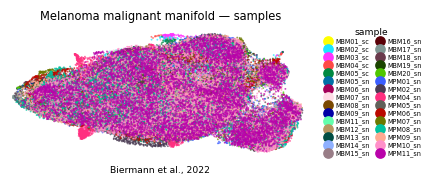

In [15]:
# save sample-integration figure on the house linear layout (single panel + external legend)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xy = plot.obsm['X_umap']
xlo,xhi = np.percentile(xy[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xy[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=6, alpha=.7, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.2, columnspacing=.6, fontsize=4.2, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Melanoma malignant manifold \u2014 samples', size=7.5)
ax.text(.5, -.13, 'Biermann et al., 2022', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', adata.shape[0])